# The First model

**Specs**: Yolov26-seg<br>
**Image-augmentation**: horizontal flip, blur, brightness, affine, noise<br>
**Cons**: the model added another class called background that is throwing hte results off
      dataset can be more diverse. model must perform better

## Adding the dataset from kaggle

In [ ]:
from datasets import load_dataset

ds = load_dataset("ngres/IGVC-Segmentation")

Resolving data files:   0%|          | 0/1793 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/122 [00:00<?, ?it/s]

In [ ]:
print(ds)
print(ds['train'].features)

DatasetDict({
    train: Dataset({
        features: ['image', 'obstacle_mask', 'lane_mask'],
        num_rows: 1024
    })
    test: Dataset({
        features: ['image', 'obstacle_mask', 'lane_mask'],
        num_rows: 62
    })
})
{'image': Image(mode=None, decode=True), 'obstacle_mask': Image(mode=None, decode=True), 'lane_mask': Image(mode=None, decode=True)}


In [ ]:
sample = ds['train'][0]
print(sample['image'])
print(type(sample['image']))

<PIL.PngImagePlugin.PngImageFile image mode=RGB size=1280x720 at 0x7C26BF7CF650>
<class 'PIL.PngImagePlugin.PngImageFile'>


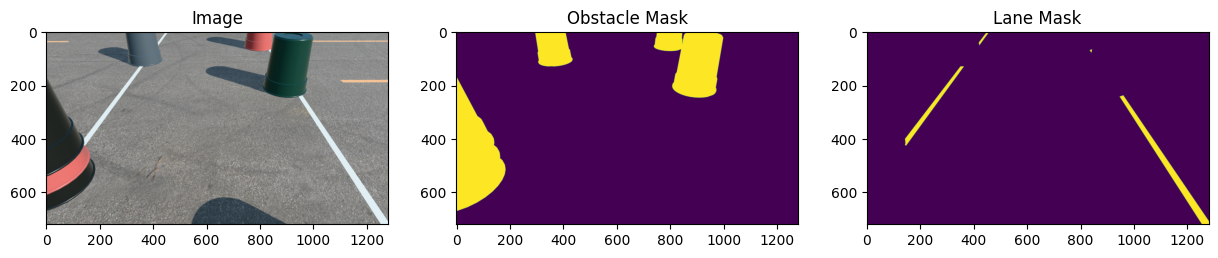

In [ ]:
import matplotlib.pyplot as plt

sample = ds['train'][0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample['image']);        axes[0].set_title("Image")
axes[1].imshow(sample['obstacle_mask']); axes[1].set_title("Obstacle Mask")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Save raw dataset images and masks
from pathlib import Path
import numpy as np

save_path = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/raw")

for split in ["train", "test"]:
    Path(f"{save_path}/{split}/images").mkdir(parents=True, exist_ok=True)
    Path(f"{save_path}/{split}/obstacle_masks").mkdir(parents=True, exist_ok=True)

    for i, sample in enumerate(ds[split]):
        sample['image'].save(f"{save_path}/{split}/images/{i}.jpg")
        sample['obstacle_mask'].save(f"{save_path}/{split}/obstacle_masks/{i}.png")

        if i % 100 == 0:
            print(f"{split}: {i} saved...")

print("Raw dataset saved!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train: 0 saved...
train: 100 saved...
train: 200 saved...
train: 300 saved...
train: 400 saved...
train: 500 saved...
train: 600 saved...
train: 700 saved...
train: 800 saved...
train: 900 saved...
train: 1000 saved...
test: 0 saved...
Raw dataset saved!


## Preprocessing the data

In [ ]:
pip install -q albumentations opencv-python

In [ ]:
import cv2
import random
import numpy as np
from pathlib import Path
import albumentations as A

targets = {
    "train": 2400,
    "test": 62
}

for split in ["train", "test"]:
    images_dir = Path(f"/content/drive/MyDrive/IGVC_dataset_ISRO/raw/{split}/images")
    masks_dir = Path(f"/content/drive/MyDrive/IGVC_dataset_ISRO/raw/{split}/obstacle_masks")

    transform = A.Compose([
        A.HorizontalFlip(p=0.5),

        A.Affine(
            scale=(0.9, 1.1),
            translate_percent=(-0.05, 0.05),
            rotate=(-10, 10),
            interpolation=cv2.INTER_LINEAR,
            mask_interpolation=cv2.INTER_NEAREST,
            p=0.7
        ),

        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5
        ),

        A.GaussNoise(
            std_range=(0.05, 0.15),
            p=0.3
        ),

        A.Blur(
            blur_limit=(3, 7),
            p=0.2
        )
    ])

    valid_exts = {".jpg", ".jpeg", ".png"}

    image_files = [
        f for f in images_dir.iterdir()
        if f.suffix.lower() in valid_exts
    ]

    current_count = len(image_files)

    target_size = targets[split]

    print(f"\n===== {split.upper()} =====")
    print(f"Current images : {current_count}")
    print(f"Target images  : {target_size}")

    needed = max(0, target_size - current_count)
    print(f"Need to generate: {needed}")
    generated = 0
    while generated < needed:

        img_path = random.choice(image_files)
        stem = img_path.stem
        mask_path = masks_dir / f"{stem}.png"

        if not mask_path.exists():
            continue

        image = cv2.imread(str(img_path))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            continue
        augmented = transform(image=image,mask=mask)

        aug_img = augmented["image"]
        aug_mask = augmented["mask"]

        _, aug_mask = cv2.threshold(aug_mask,127,255,cv2.THRESH_BINARY)
        aug_img = cv2.cvtColor(
            aug_img,
            cv2.COLOR_RGB2BGR
        )
        new_stem = f"{stem}_aug_{generated}"
        new_img_path = images_dir / f"{new_stem}.jpg"
        new_mask_path = masks_dir / f"{new_stem}.png"
        cv2.imwrite(str(new_img_path), aug_img)
        cv2.imwrite(str(new_mask_path), aug_mask)
        generated += 1
        if generated % 50 == 0:
            print(f"{split}: {generated}/{needed}")
    print(
        f"{split} complete. "
        f"Added {generated} images.")
print("\nAll augmentations finished.")


===== TRAIN =====
Current images : 1024
Target images  : 2400
Need to generate: 1376
train: 50/1376
train: 100/1376
train: 150/1376
train: 200/1376
train: 250/1376
train: 300/1376
train: 350/1376
train: 400/1376
train: 450/1376
train: 500/1376
train: 550/1376
train: 600/1376
train: 650/1376
train: 700/1376
train: 750/1376
train: 800/1376
train: 850/1376
train: 900/1376
train: 950/1376
train: 1000/1376
train: 1050/1376
train: 1100/1376
train: 1150/1376
train: 1200/1376
train: 1250/1376
train: 1300/1376
train: 1350/1376
train complete. Added 1376 images.

===== TEST =====
Current images : 62
Target images  : 62
Need to generate: 0
test complete. Added 0 images.

All augmentations finished.


## Converting the obstacle mask to yolo seg

In [ ]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image

def mask_to_yolo(mask_pil, class_id, img_w, img_h):
    mask_np = np.array(mask_pil.convert("L"))
    _, binary = cv2.threshold(mask_np, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    lines = []
    for contour in contours:
        if cv2.contourArea(contour) < 100:
            continue
        coords = contour.reshape(-1, 2)
        normalized = coords / [img_w, img_h]
        flat = normalized.flatten().tolist()
        lines.append(f"{class_id} " + " ".join(f"{v:.6f}" for v in flat))
    return lines

yolo_path = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2")
raw_path  = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/raw")

for split in ["train", "test"]:
    Path(f"{yolo_path}/images/{split}").mkdir(parents=True, exist_ok=True)
    Path(f"{yolo_path}/labels/{split}").mkdir(parents=True, exist_ok=True)

    src_images = raw_path / split / "images"
    src_masks  = raw_path / split / "obstacle_masks"
    image_files = list(src_images.glob("*"))

    for i, image_path in enumerate(image_files):
        stem = image_path.stem
        mask_path = src_masks / f"{stem}.png"

        img  = Image.open(image_path)
        mask = Image.open(mask_path)
        w, h = img.size

        img.save(f"{yolo_path}/images/{split}/{i}.jpg")

        # class 0 = obstacle
        lines  = mask_to_yolo(mask, 0, w, h)

        # class 1 = path (inverted mask)
        inverted = Image.fromarray(255 - np.array(mask.convert("L")))
        lines   += mask_to_yolo(inverted, 1, w, h)

        with open(f"{yolo_path}/labels/{split}/{i}.txt", "w") as f:
            f.write("\n".join(lines))

        if i % 100 == 0:
            print(f"{split}: {i} converted...")

print("Done!")

train: 0 converted...
train: 100 converted...
train: 200 converted...
train: 300 converted...
train: 400 converted...
train: 500 converted...
train: 600 converted...
train: 700 converted...
train: 800 converted...
train: 900 converted...
train: 1000 converted...
train: 1100 converted...
train: 1200 converted...
train: 1300 converted...
train: 1400 converted...
train: 1500 converted...
train: 1600 converted...
train: 1700 converted...
train: 1800 converted...
train: 1900 converted...
train: 2000 converted...
train: 2100 converted...
train: 2200 converted...
train: 2300 converted...
test: 0 converted...
Done!


### Saving the yaml file

In [ ]:
yaml_content = """
path: /content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2
train: images/train
val: images/test

nc: 2
names:
  0: obstacle
  1: path
"""

with open("/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2/igvc.yaml", "w") as f:
    f.write(yaml_content)

print("YAML saved!")

YAML saved!


### Printing the converted image from mask to *yolo*

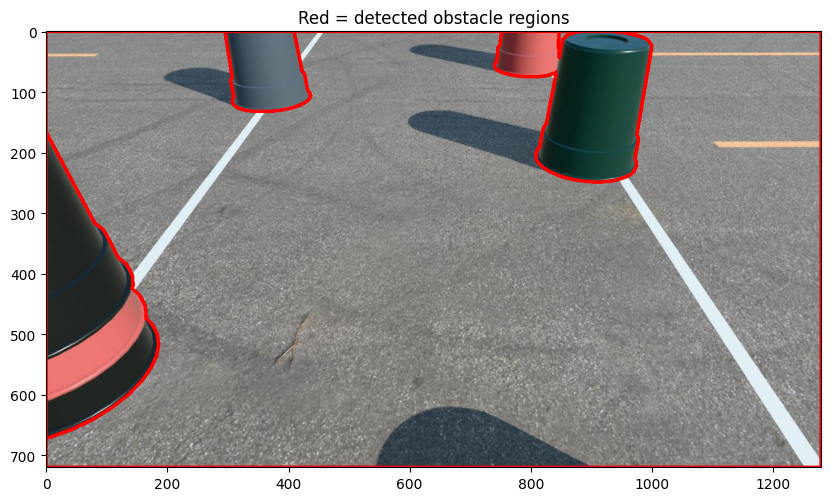

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import numpy as np

def verify_label(image_path, label_path):
    img = np.array(Image.open(image_path))
    h, w = img.shape[:2]

    fig, ax = plt.subplots(1, figsize=(10, 6))
    ax.imshow(img)

    with open(label_path) as f:
        for line in f.readlines():
            values = line.strip().split()
            class_id = values[0]
            coords = list(map(float, values[1:]))

            # convert back from normalized to pixel coords
            points = np.array(coords).reshape(-1, 2)
            points *= [w, h]

            polygon = plt.Polygon(points, fill=False, edgecolor='red', linewidth=2)
            ax.add_patch(polygon)

    plt.title("Red = detected obstacle regions")
    plt.show()

# Run it on first sample
verify_label(
    f"{yolo_path}/images/train/0.jpg",
    f"{yolo_path}/labels/train/0.txt"
)

## Run only when switching from different envirnoments

In [ ]:
# Step 1: mount drive
from google.colab import drive
drive.mount('/content/drive')

# Step 2: verify your data is actually visible
import os
print(os.listdir("/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2"))

# Step 3: recreate yaml (just in case)
yaml_content = """path: /content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2
train: images/train
val: images/val
test: images/test

nc: 2
names:
  0: obstacle
  1: path
"""
with open("/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2/igvc.yaml", "w") as f:
    f.write(yaml_content)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['images', 'labels', 'igvc.yaml']


## Training in yolo26sem

In [ ]:
pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.4 MB/s eta 0:00:00


In [ ]:
import shutil
import random
from pathlib import Path

base = Path("/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2")

train_images = base / "images" / "train"
train_labels = base / "labels" / "train"

(base / "images" / "val").mkdir(parents=True, exist_ok=True)
(base / "labels" / "val").mkdir(parents=True, exist_ok=True)

all_images = sorted(list(train_images.glob("*.jpg")))
random.seed(42)
random.shuffle(all_images)

total       = len(all_images)
n_train     = int(total * 0.75)
n_val       = int(total * 0.12)

train_files = all_images[:n_train]
val_files   = all_images[n_train:n_train + n_val]

for img_path in val_files:
    stem = img_path.stem
    lbl_path = train_labels / f"{stem}.txt"

    shutil.move(str(img_path),  str(base / "images" / "val" / img_path.name))
    if lbl_path.exists():
        shutil.move(str(lbl_path), str(base / "labels" / "val" / f"{stem}.txt"))

print("Split done!")

Split done!


In [ ]:
yaml_content = """
path: /content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2
train: images/train
val: images/val
test: images/test

nc: 2
names:
  0: obstacle
  1: path
"""

with open(base / "igvc.yaml", "w") as f:
    f.write(yaml_content)

print("YAML saved!")

YAML saved!


In [ ]:
for split in ["train", "val", "test"]:
    imgs = list((base / "images" / split).glob("*.jpg"))
    lbls = list((base / "labels" / split).glob("*.txt"))
    print(f"{split}: {len(imgs)} images, {len(lbls)} labels")

train: 0 images, 0 labels
val: 0 images, 0 labels
test: 0 images, 0 labels


In [ ]:
from ultralytics import YOLO
model = YOLO("yolo26n-sem.pt")
path = "/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2"
results = model.train(data=f"{path}/igvc.yaml", epochs=100,imgsz=640,batch=8,
    project="/content/drive/MyDrive/IGVC_dataset_ISRO/runs",
    name="run1",    plots=True,
    val=True, )

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2/igvc.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, h

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1-2/weights/best.pt")

metrics = model.val(
    data="/content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2/igvc.yaml",
    split="test"
)


Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-sem summary (fused): 73 layers, 1,625,742 parameters, 0 gradients, 4.3 GFLOPs
val: Fast image access ✅ (ping: 0.9±0.8 ms, read: 0.2±0.1 MB/s, size: 130.9 KB)
val: Scanning /content/drive/MyDrive/IGVC_dataset_ISRO/yolo_format_2/labels/test.cache... 62 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 62/62 9.6Mit/s 0.0s
                 Class     Images     Pixels       mIoU     PixAcc: 100% ━━━━━━━━━━━━ 4/4 11.8s/it 47.3s
                   all         62   15052800      0.629      0.987
              obstacle         58    1874090      0.902      0.989
                  path         62   13178710      0.985      0.986
            background          0          0          0          0
Speed: 3.6ms preprocess, 6.8ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /content/runs/semantic/val


## Results

In [ ]:
import numpy as np
from ultralytics import YOLO
print("mIoU:", metrics.miou)
print("Pixel Accuracy:", metrics.pixel_accuracy)
print("Per-class IoU:", metrics.per_class_iou)
print(metrics.names)
print("Classes:", metrics.names)
print("Pixels per class:", metrics.nt_per_class)
print("Images per class:", metrics.nt_per_image)
print(type(metrics.confusion_matrix))
cm = metrics.confusion_matrix.matrix
print(cm)
# cm = np.array(cm, dtype=float)
cm = cm[:2, :2]
classes = ["obstacle", "path"]

TP = np.trace(cm)
FP = cm.sum(axis=0).sum() - TP
FN = cm.sum(axis=1).sum() - TP
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score:  {f1:.4f} ({f1*100:.2f}%)")

for i, cls in enumerate(classes):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP

    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * precision * recall / (precision + recall)

    print(f"\n{cls}")
    print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
    print(f"Recall:    {recall:.4f} ({recall*100:.2f}%)")
    print(f"F1 Score:  {f1:.4f} ({f1*100:.2f}%)")

mIoU: 0.6288453340530396
Pixel Accuracy: 0.9865964651107788
Per-class IoU: [    0.90182     0.98471           0]
{0: 'obstacle', 1: 'path', 2: 'background'}
Classes: {0: 'obstacle', 1: 'path', 2: 'background'}
Pixels per class: [ 1874090 13178710        0]
Images per class: [58 62  0]
<class 'ultralytics.utils.metrics.ConfusionMatrix'>
[[ 1.8533e+06  1.8095e+05           0]
 [      20810  1.2998e+07           0]
 [          0           0           0]]
Precision: 0.9866 (98.66%)
Recall:    0.9866 (98.66%)
F1 Score:  0.9866 (98.66%)

obstacle
Precision: 0.9889 (98.89%)
Recall:    0.9110 (91.10%)
F1 Score:  0.9484 (94.84%)

path
Precision: 0.9863 (98.63%)
Recall:    0.9984 (99.84%)
F1 Score:  0.9923 (99.23%)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

image 1/1 /content/drive/MyDrive/test_img.jpg: 480x640 37.1ms
Speed: 10.0ms preprocess, 37.1ms inference, 48.9ms postprocess per image at shape (1, 3, 480, 640)


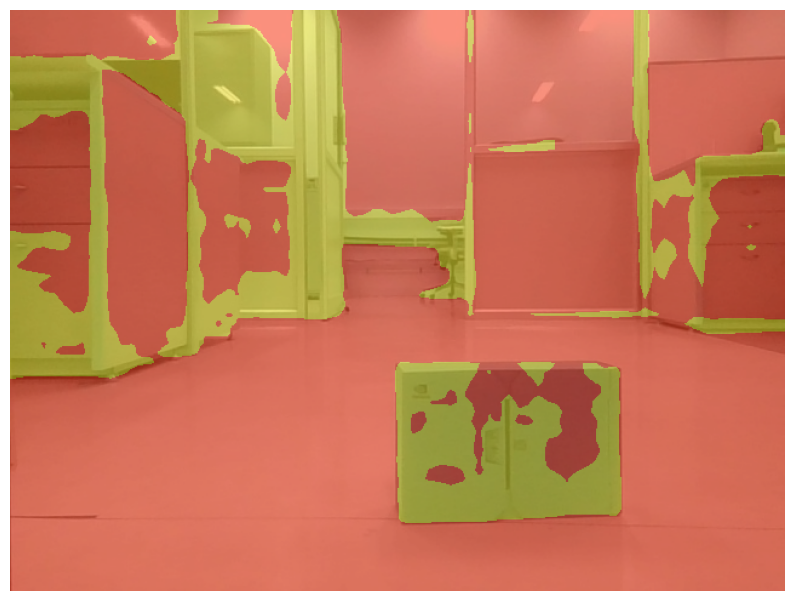

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image

# Load model
model = YOLO("/content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1-2/weights/best.pt")

path = "/content/drive/MyDrive/test_img.jpg",

# Run inference
results = model.predict(
    source=path,
    save=False,
    conf=0.25
)

# Get plotted image with masks

annotated_img = results[0].plot()
# Display
plt.figure(figsize=(10, 10))
plt.imshow(annotated_img)
plt.axis("off")
plt.show()